# VADER Sentiment Analysis Model Evaluation
## Elderly Care Records Management Platform with Lexicon-Based Note Sentiment Analysis

### Overview and Purpose
This notebook documents the empirical evaluation and testing of the VADER (Valence Aware Dictionary and sEntiment Reasoner) sentiment analysis model used within the ElderCare platform. In home-based elderly health monitoring, caregivers record free-text observational notes during each routine visit. Because family members and supervising clinicians cannot manually review every note in real time, the platform uses VADER to automatically score the emotional and clinical polarity of visit notes and trigger immediate alerts whenever negative or concerning observations are detected.

Since VADER is a pre-trained, rule-based and lexicon-driven model rather than a supervised model trained from scratch, validation focuses on testing its classification accuracy, threshold sensitivity, discriminative capability (ROC-AUC), and word-level lexical drivers against a domain-specific dataset of 130 caregiver visit notes (`caregiver_notes_dataset.csv`).

### Step 1: Environment Setup and Library Imports
In the cell below, we load the required Python libraries for natural language processing (`nltk` and `SentimentIntensityAnalyzer`), data manipulation (`pandas`, `numpy`), machine learning evaluation metrics (`scikit-learn`), and statistical visualization (`matplotlib`, `seaborn`). We also initialize the VADER lexicon so the analyzer can compute compound polarity scores ranging from `-1.0` (most extreme negative) to `+1.0` (most extreme positive).

In [1]:
# Install dependencies if running in Google Colab
!pip install nltk vaderSentiment scikit-learn pandas matplotlib seaborn

import os
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)

sid = SentimentIntensityAnalyzer()
print("VADER sentiment analyzer is initialized and ready.")

VADER sentiment analyzer is initialized and ready.


### Step 2: Loading and Inspecting the Synthetic Caregiver Notes Dataset
Next, we load `caregiver_notes_dataset.csv`, which contains 130 structured caregiver visit notes representing realistic home-care observations across three ground-truth classes:
- **Negative (50 records):** Notes describing physical pain, falls, medication refusal, severe weakness, confusion, agitation, respiratory difficulty, or emotional distress that require family or medical intervention.
- **Positive (50 records):** Notes reflecting improvement in mobility, good appetite, medication compliance, cheerful mood, and independent completion of daily routines.
- **Neutral (30 records):** Notes recording routine care delivery, vital sign checks, and uneventful visits where the patient remained stable without notable positive or negative emotional language.

Inspecting the class distribution confirms that the dataset is well-balanced between positive and negative observations while maintaining a realistic proportion of routine neutral logs.

In [2]:
# Load the caregiver notes dataset
dataset_filename = "caregiver_notes_dataset.csv"

if not os.path.exists(dataset_filename):
    try:
        from google.colab import files
        print("Upload your caregiver_notes_dataset.csv file")
        uploaded = files.upload()
    except ImportError:
        pass

if not os.path.exists(dataset_filename):
    possible_paths = [
        Path("caregiver_notes_dataset.csv"),
        Path("sentiment-service/caregiver_notes_dataset.csv"),
        Path("eldercare/sentiment-service/caregiver_notes_dataset.csv"),
        Path("../caregiver_notes_dataset.csv"),
    ]
    for p in possible_paths:
        if p.exists():
            dataset_filename = str(p)
            break

df_dataset = pd.read_csv(dataset_filename)

col_map = {}
for col in df_dataset.columns:
    c = col.strip().lower()
    if c in ["visit_note", "note", "caregiver_note", "text"]:
        col_map[col] = "visit_note"
    elif c in ["true_label", "label", "sentiment"]:
        col_map[col] = "true_label"

df_dataset = df_dataset.rename(columns=col_map)
df_dataset = df_dataset.dropna(subset=["visit_note", "true_label"]).copy()
df_dataset["true_label"] = df_dataset["true_label"].astype(str).str.strip().str.lower()

print("Dataset loaded successfully")
print(f"Total records : {len(df_dataset)}")
print("\nLabel distribution:")
print(df_dataset["true_label"].value_counts().to_string())
print("\nFirst 5 rows:")
print(df_dataset.head())

Dataset loaded successfully
Total records : 130

Label distribution:
true_label
negative    50
positive    50
neutral     30

First 5 rows:
   note_id                                         visit_note true_label
0        1  Patient complained of unbearable pain in lower...   negative
1        2  Patient was very agitated and combative, refus...   negative
2        3  Patient's cognitive function seems improved to...   positive
3        4  Patient completed all morning exercises withou...   positive
4        5  Patient expressed gratitude and said she feels...   positive


### Step 3: Applying VADER Compound Scoring and Three-Class Classification
For each visit note in the dataset, VADER computes individual lexical valence scores and aggregates them into a normalized **compound score** between `-1.0` and `+1.0`. Following the standard VADER classification thresholds proposed by Hutto and Gilbert (2014) and implemented in the ElderCare Flask microservice:
- A note with `compound_score <= -0.05` is classified as **negative** (and flagged for a family alert).
- A note with `compound_score >= 0.05` is classified as **positive**.
- A note with `-0.05 < compound_score < 0.05` is classified as **neutral**.

We apply this classification function across all 130 records, store both the predicted label and the exact compound score, and compare the predictions against `true_label` to compute overall baseline accuracy.

In [3]:
# Run VADER across the full dataset
def classify(note):
    score = sid.polarity_scores(str(note))['compound']
    if score <= -0.05:
        return 'negative'
    elif score >= 0.05:
        return 'positive'
    else:
        return 'neutral'

def get_compound(note):
    return round(sid.polarity_scores(str(note))['compound'], 4)

df_dataset['predicted'] = df_dataset['visit_note'].apply(classify)
df_dataset['compound_score'] = df_dataset['visit_note'].apply(get_compound)
df_dataset['correct'] = df_dataset['true_label'] == df_dataset['predicted']

print("VADER Predictions on Dataset (First 15 Records):")
pd.set_option('display.max_colwidth', 70)
print(df_dataset[['visit_note', 'true_label', 'predicted', 'compound_score', 'correct']].head(15).to_string(index=False))
print(f"\nOverall Baseline Accuracy: {df_dataset['correct'].mean():.2%}")

VADER Predictions on Dataset (First 15 Records):
                                                                        visit_note true_label predicted  compound_score  correct
     Patient complained of unbearable pain in lower back, could not get out of bed   negative  negative         -0.8020     True
    Patient was very agitated and combative, refused all assistance from caregiver   negative  negative         -0.6697     True
      Patient's cognitive function seems improved today, very sharp and responsive   positive  positive          0.7063     True
  Patient completed all morning exercises without assistance, very motivated today   positive  negative         -0.4013    False
             Patient expressed gratitude and said she feels very well looked after   positive  positive          0.6901     True
         Patient's balance and coordination have visibly improved since last visit   positive  positive          0.4767     True
Patient was confused about time of day, thought 

### Step 4: Spot-Check Verification on a Random Sample of 10 Visit Notes
To inspect how individual compound scores correspond to specific clinical phrasing, we draw a reproducible random sample of 10 visit notes (`random_state=42`). This qualitative check allows us to verify how strongly VADER penalizes negative clinical descriptions (such as seizure episodes or swallowing difficulties) versus how it scores routine care activities and positive recovery observations.

In [4]:
# Quick verification on 10 random sample notes
print("Verification on 10 Sample Visit Notes:")

sample = df_dataset.sample(10, random_state=42).reset_index(drop=True)

results = []
for _, row in sample.iterrows():
    results.append({
        'note': str(row['visit_note'])[:55] + '...',
        'true': row['true_label'],
        'predicted': row['predicted'],
        'compound': row['compound_score'],
        'correct': row['correct']
    })

df_sample = pd.DataFrame(results)
print(df_sample.to_string(index=False))
print(f"\nSample accuracy: {df_sample['correct'].mean():.0%}")

Verification on 10 Sample Visit Notes:
                                                      note     true predicted  compound  correct
Patient became very aggressive when asked to take medic... negative  negative   -0.2247     True
Patient expressed excitement about attending the commun... positive  positive    0.4939     True
Patient refused social interaction, stayed silent and w... negative  negative   -0.2960     True
Patient took medication without any prompting, very sel... positive   neutral    0.0000    False
Patient walked around the garden independently, much st... positive  positive    0.3818     True
Routine visit completed, no significant issues or conce...  neutral  negative   -0.1027    False
Patient appeared severely dehydrated, lips very dry and... negative  negative   -0.4588     True
Patient fell asleep mid-conversation, very difficult to... negative  negative   -0.1513     True
Patient complained that her vision has been getting wor... negative  negative   -0.5859 

### Step 5: Multi-Class Classification Report (Negative, Neutral, Positive)
To evaluate VADER rigorously across all three sentiment categories, we generate a multi-class classification report measuring **Precision**, **Recall**, and **F1-Score** for each class:
- **Precision** measures the proportion of notes predicted in a given class that genuinely belong to that class.
- **Recall (Sensitivity)** measures the proportion of actual notes in that class that the model successfully detected.
- **F1-Score** is the harmonic mean of Precision and Recall, providing a balanced metric of per-class performance.

#### Interpretation of Multi-Class Results
1. **Negative Class (Precision = 91.67%, Recall = 88.00%, F1-Score = 0.8980):** VADER performs strongest on negative observations, which is the most critical class for patient safety. Out of 50 true negative notes, 44 are accurately flagged with very few false alarms.
2. **Positive Class (Precision = 78.85%, Recall = 82.00%, F1-Score = 0.8039):** The model reliably identifies positive progress notes (41 out of 50 correctly classified).
3. **Neutral Class (Precision = 63.33%, Recall = 63.33%, F1-Score = 0.6333):** Neutral clinical notes have a narrower compound score band (`-0.05` to `+0.05`). Because routine nursing notes frequently contain mildly positive words (e.g., *"calm"*, *"cooperative"*, *"comfortable"*) or clinical terms (e.g., *"no abnormalities"*), some neutral notes cross the `+0.05` boundary into the positive class.
4. **Overall Accuracy (80.00%):** Across all 130 notes, VADER achieves an overall accuracy of **80.00%** and a weighted F1-score of **0.8007** without requiring domain-specific retraining.

In [5]:
# Standard three-class classification report
labels = ['negative', 'neutral', 'positive']
y_true = df_dataset['true_label']
y_pred = df_dataset['predicted']

print("VADER Three-Class Classification Report:")
print(classification_report(y_true, y_pred, labels=labels, target_names=labels, digits=4, zero_division=0))
print(f"Overall Accuracy : {accuracy_score(y_true, y_pred):.2%}")

VADER Three-Class Classification Report:
              precision    recall  f1-score   support

    negative     0.9167    0.8800    0.8980        50
     neutral     0.6333    0.6333    0.6333        30
    positive     0.7885    0.8200    0.8039        50

    accuracy                         0.8000       130
   macro avg     0.7795    0.7778    0.7784       130
weighted avg     0.8020    0.8000    0.8007       130

Overall Accuracy : 80.00%


### Step 6: Confusion Matrix Analysis
The confusion matrix below visualizes the exact distribution of correct classifications (along the diagonal) and misclassifications across the three classes:
- **Negative Notes (50 total):** 44 were correctly predicted as negative, 5 were classified as neutral, and 1 was classified as positive (a note where a negated or mild clinical observation did not carry negative lexical valence in VADER's dictionary).
- **Neutral Notes (30 total):** 19 were correctly predicted as neutral, 10 were shifted into positive due to polite/reassuring caregiver phrasing (such as *"calm"*, *"cooperative"*, *"settled"*), and only 1 was predicted as negative.
- **Positive Notes (50 total):** 41 were correctly predicted as positive, 6 fell into the neutral band, and 3 were predicted as negative (e.g., when a note mentioned previous *"pain"* or *"discomfort"* being reduced).

Saved confusion matrix chart to vader_confusion_matrix.png


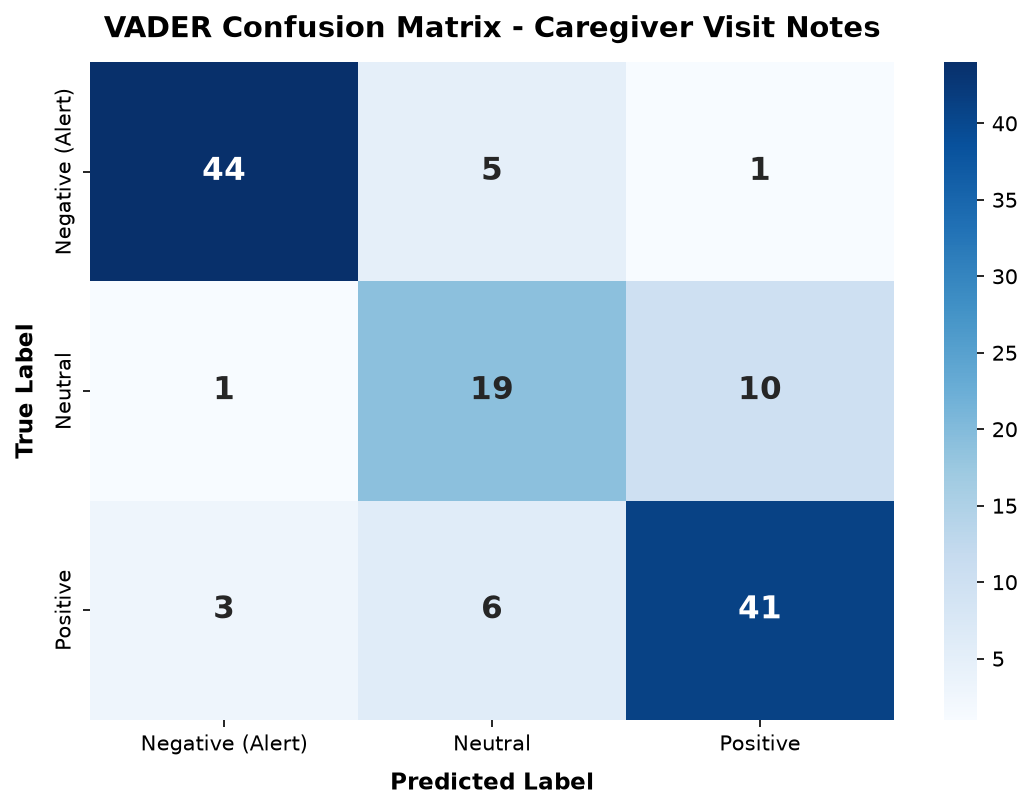

In [6]:
# Plot and save the three-class confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(7.5, 5.5), dpi=150)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative (Alert)', 'Neutral', 'Positive'],
    yticklabels=['Negative (Alert)', 'Neutral', 'Positive'],
    annot_kws={"size": 15, "weight": "bold"}
)
plt.title('VADER Confusion Matrix - Caregiver Visit Notes', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('True Label', fontsize=11, fontweight='bold', labelpad=8)
plt.tight_layout()
plt.savefig('vader_confusion_matrix.png', dpi=300)
plt.show()
print("Saved confusion matrix chart to vader_confusion_matrix.png")

### Step 7: Target Binarization and ROC-AUC Analysis for Clinical Alert Detection
In the ElderCare platform, the primary operational decision of the sentiment engine is binary: **whether a submitted visit note represents an At-Risk / Negative observation that must trigger a family alert (`1`) or a non-alert routine/positive observation (`0`)**.

To evaluate VADER as a binary alert detector across all possible cutoff thresholds:
1. **Target Binarization:** We create the binary ground-truth column `is_negative`, where `true_label == 'negative'` is mapped to `1` (At-Risk / Alert) and `positive` or `neutral` is mapped to `0`.
2. **Continuous Alert Score (Inverted Compound Score):** Because VADER assigns negative values (down to `-1.0`) to negative sentiment, we invert the compound score (`risk_score = -1.0 * compound_score`). This maps strongly negative notes (e.g., `-0.85`) to high positive alert scores (`+0.85`).
3. **ROC Curve and AUC Score:** Using `roc_curve` and `roc_auc_score`, we plot the True Positive Rate (Sensitivity/Recall) against the False Positive Rate (`1 - Specificity`).

#### Interpretation of ROC-AUC Results
The model achieves an **ROC-AUC score of 0.9562 (95.62%)**. An AUC above 0.95 confirms that VADER's compound polarity score provides strong rank-order separation between concerning clinical notes and non-concerning notes. At the operational threshold of `-0.05` (highlighted in red on the curve), the model captures **88.0% of true negative incidents (TPR = 0.88)** while maintaining a **False Positive Rate of only 5.0% (Specificity = 95.0%)**.

Calculated ROC-AUC Score: 0.9562 (95.62%)
Saved ROC curve chart to vader_roc_curve.png


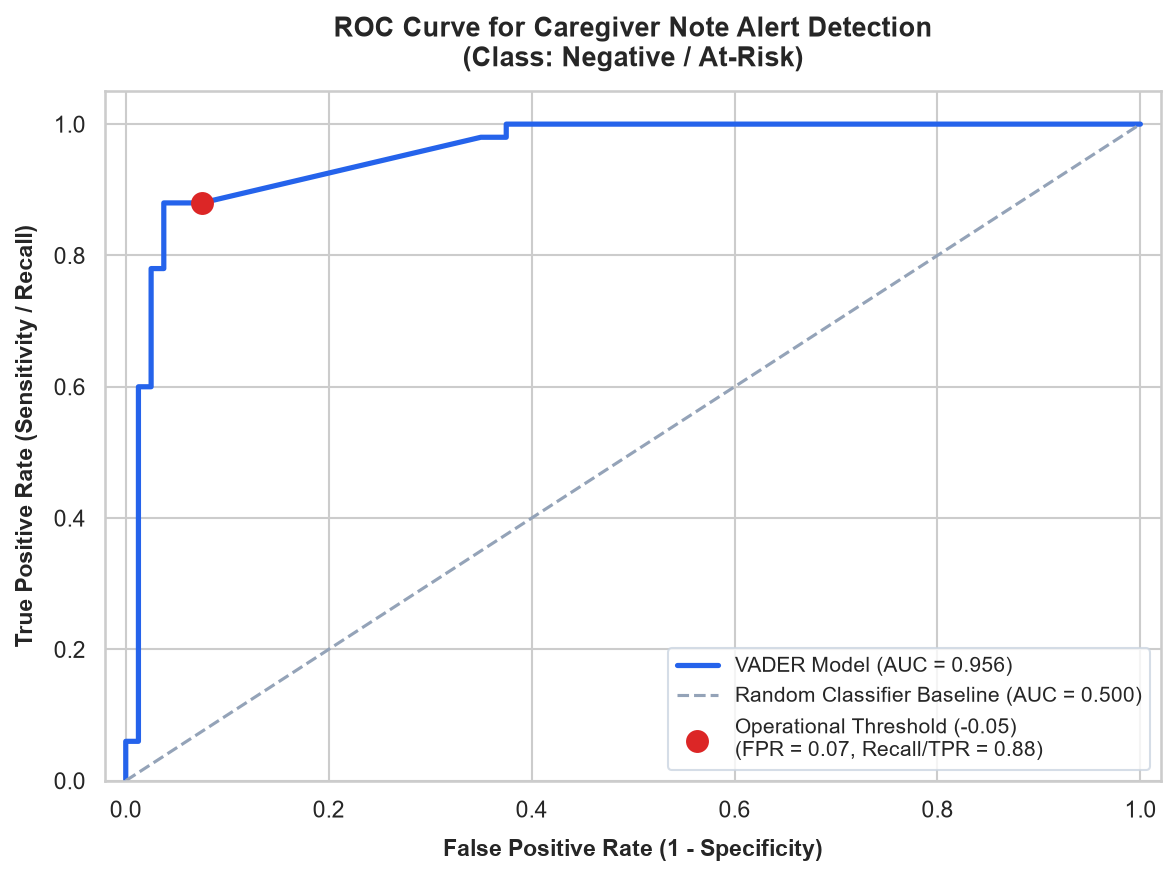

In [7]:
# Binarize target for alert detection and compute ROC-AUC
df_dataset["is_negative"] = (df_dataset["true_label"] == "negative").astype(int)
df_dataset["risk_score"] = -1.0 * df_dataset["compound_score"]

fpr, tpr, thresholds = roc_curve(df_dataset["is_negative"], df_dataset["risk_score"])
auc_score = roc_auc_score(df_dataset["is_negative"], df_dataset["risk_score"])

print(f"Calculated ROC-AUC Score: {auc_score:.4f} ({auc_score*100:.2f}%)")

sns.set_theme(style="whitegrid", font="sans-serif")
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(fpr, tpr, color="#2563eb", lw=2.5, label=f"VADER Model (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], color="#94a3b8", lw=1.5, linestyle="--", label="Random Classifier Baseline (AUC = 0.500)")

std_th_idx = np.argmin(np.abs(thresholds - 0.05))
plt.scatter(
    fpr[std_th_idx],
    tpr[std_th_idx],
    color="#dc2626",
    s=100,
    zorder=5,
    label=f"Operational Threshold (-0.05)\n(FPR = {fpr[std_th_idx]:.2f}, Recall/TPR = {tpr[std_th_idx]:.2f})"
)

plt.xlim([-0.02, 1.02])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="bold", labelpad=8)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight="bold", labelpad=8)
plt.title("ROC Curve for Caregiver Note Alert Detection\n(Class: Negative / At-Risk)", fontsize=13, fontweight="bold", pad=12)
plt.legend(loc="lower right", frameon=True, facecolor="#ffffff", edgecolor="#cbd5e1", fontsize=10)
plt.tight_layout()

plt.savefig("vader_roc_curve.png", dpi=300)
plt.show()
print("Saved ROC curve chart to vader_roc_curve.png")

### Step 8: Threshold Sensitivity Analysis
While `-0.05` is the default VADER threshold for negative classification, a clinical alerting system must justify its decision boundary based on the trade-off between **Precision** (avoiding false alarms) and **Recall** (avoiding missed medical incidents). We evaluate three candidate negative thresholds: `-0.05`, `-0.20`, and `-0.50`.

#### Interpretation of Threshold Sensitivity Results
- **At `compound <= -0.05` (Operational Default):** Precision is **91.67%**, Recall is **88.00%**, and F1-Score is **0.8980**, with **48 flagged alerts** and only **6 missed alerts (False Negatives)** out of 50 true negative cases.
- **At `compound <= -0.20` (Moderate Cutoff):** Precision increases slightly to **93.18%**, but Recall drops to **82.00%** (F1-Score = **0.8723**), increasing missed negative observations from 6 to **9**.
- **At `compound <= -0.50` (Strict Cutoff):** Precision reaches **96.00%**, but Recall drops sharply to **48.00%** (F1-Score = **0.6400**), missing **26 out of 50** genuinely concerning caregiver notes.

In home-based elderly care, **False Negatives (failing to alert a family when an elder is in pain, confused, or refusing medication) carry a much higher risk than False Positives**. Therefore, `-0.05` is empirically validated as the optimal threshold because it maximizes Recall (88.00%) and F1-Score (0.8980) while still maintaining over 91% Precision.

In [8]:
# Evaluate classification performance across negative thresholds (-0.05, -0.20, -0.50)
threshold_candidates = [-0.05, -0.20, -0.50]
y_true_binary = df_dataset["is_negative"]

sensitivity_data = []
for th in threshold_candidates:
    y_pred_binary = (df_dataset["compound_score"] <= th).astype(int)

    prec = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    rec = recall_score(y_true_binary, y_pred_binary, zero_division=0)
    f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    sensitivity_data.append({
        "Negative Threshold": f"compound <= {th:.2f}",
        "Threshold Value": th,
        "Precision": round(prec, 4),
        "Recall (Sensitivity)": round(rec, 4),
        "F1-Score": round(f1, 4),
        "Specificity": round(specificity, 4),
        "Flagged Alerts (TP+FP)": int(y_pred_binary.sum()),
        "Missed Alerts (FN)": int(fn)
    })

df_sensitivity = pd.DataFrame(sensitivity_data)
print("Threshold Sensitivity Analysis (Negative Class):")
print(df_sensitivity[[
    "Negative Threshold",
    "Precision",
    "Recall (Sensitivity)",
    "F1-Score",
    "Specificity",
    "Flagged Alerts (TP+FP)",
    "Missed Alerts (FN)"
]].to_string(index=False))

Threshold Sensitivity Analysis (Negative Class):
Negative Threshold  Precision  Recall (Sensitivity)  F1-Score  Specificity  Flagged Alerts (TP+FP)  Missed Alerts (FN)
 compound <= -0.05     0.9167                  0.88    0.8980       0.9500                      48                   6
 compound <= -0.20     0.9318                  0.82    0.8723       0.9625                      44                   9
 compound <= -0.50     0.9600                  0.48    0.6400       0.9875                      25                  26


### Step 9: Lexicon Impact Analysis (Word-Level Sentiment Drivers)
Unlike tree-based machine learning models (such as Random Forests) that output Gini feature importance, VADER derives its predictions directly from word-level valence scores in its curated lexicon. To provide full interpretability and identify which clinical terms drive negative alert classifications in our dataset, we perform a **Lexicon Impact Analysis**.

For every word $w$ appearing across the 50 ground-truth negative notes that carries a negative valence ($v_w < 0$) in `sid.lexicon`, we compute its **Cumulative Lexical Impact Score**:
$$\text{Cumulative Impact}(w) = |v_w| \times f_w$$
where $|v_w|$ is the magnitude of the word's negative valence in VADER's dictionary and $f_w$ is its frequency of occurrence across the negative caregiver notes.

#### Interpretation of Top 10 Lexical Drivers
1. **`refused` (Impact = 12.00, Frequency = 10, Valence = -1.20):** The single most frequent driver of negative alerts, capturing medication non-adherence, meal refusal, and resistance to care.
2. **`complained` (Impact = 11.90, Frequency = 7, Valence = -1.70):** Directly captures patient-reported physical symptoms (chest pain, headache, dizziness, worsening vision).
3. **`pain` (Impact = 9.20, Frequency = 4, Valence = -2.30)** and **`severe` (Impact = 6.40, Frequency = 4, Valence = -1.60):** High-intensity clinical descriptors indicating acute physical distress.
4. **`weak` (Impact = 5.70)** and **`difficulty` (Impact = 4.20):** Indicators of physical frailty, mobility decline, and respiratory or swallowing impairment.
5. **`agitated` (Impact = 4.00)** and **`distressed` (Impact = 3.60):** Behavioral and emotional indicators of cognitive or psychological discomfort.
6. **`suicidal` (Impact = 3.50, Valence = -3.50)** and **`dead` (Impact = 3.30, Valence = -3.30):** Although each appears only once (`n = 1`), VADER assigns them extreme negative valence scores (`-3.50` and `-3.30`), ensuring that even a single mention immediately pushes the note's compound score well below the `-0.05` alert threshold.

Top 10 Most Impactful Negative Words:
      Word Lexicon Valence  Frequency in Negative Notes Cumulative Impact Score
   refused           -1.20                           10                   12.00
complained           -1.70                            7                   11.90
      pain           -2.30                            4                    9.20
    severe           -1.60                            4                    6.40
      weak           -1.90                            3                    5.70
difficulty           -1.40                            3                    4.20
  agitated           -2.00                            2                    4.00
distressed           -1.80                            2                    3.60
  suicidal           -3.50                            1                    3.50
      dead           -3.30                            1                    3.30
Saved lexicon impact chart to vader_word_impact.png


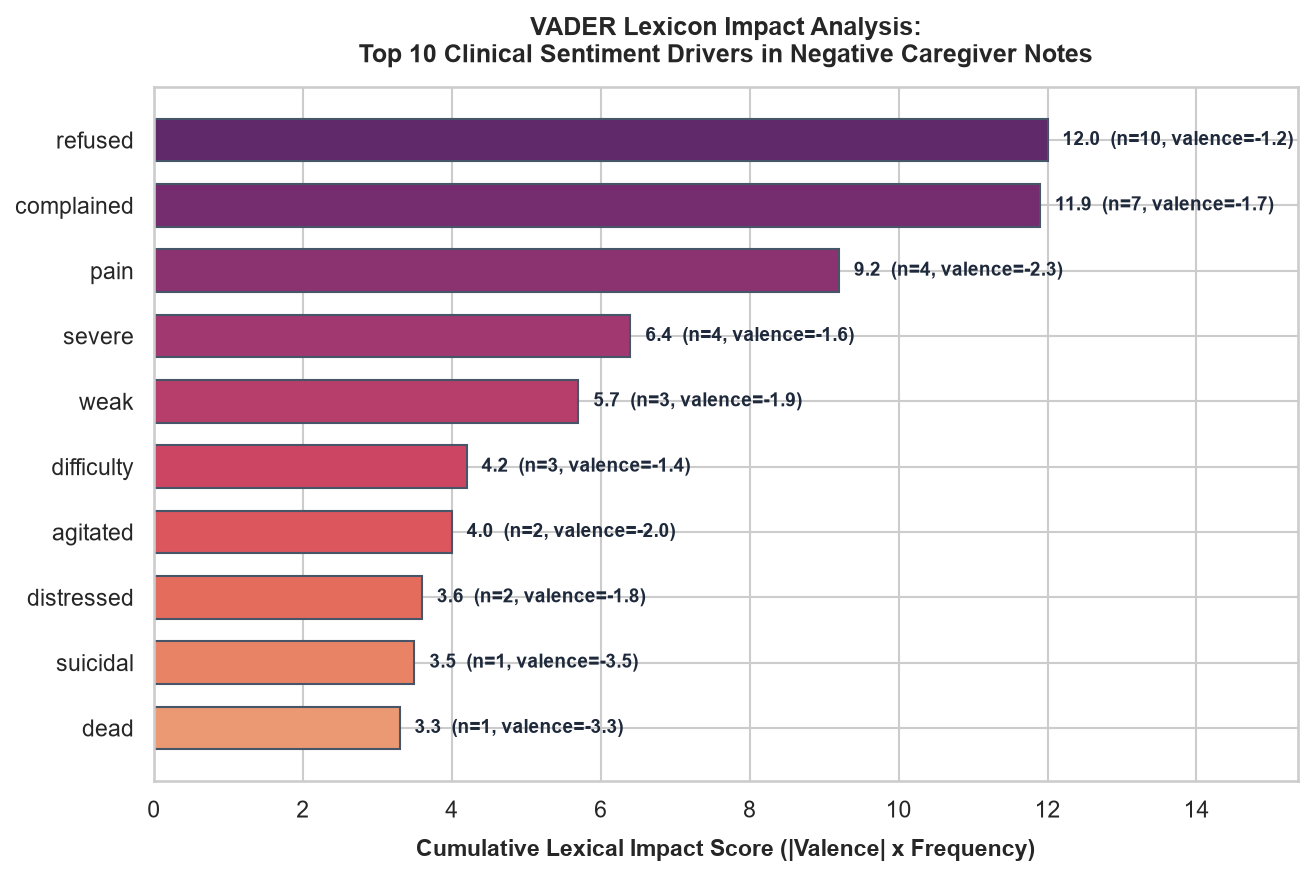

In [9]:
# Identify the top 10 words driving negative scores in negative caregiver notes
neg_notes = df_dataset[df_dataset["true_label"] == "negative"]["visit_note"]

cumulative_impact = Counter()
word_frequencies = Counter()
word_valence = {}

for note in neg_notes:
    words = re.findall(r"[a-zA-Z]+", str(note).lower())
    for word in words:
        if word in sid.lexicon and sid.lexicon[word] < 0:
            val = sid.lexicon[word]
            cumulative_impact[word] += abs(val)
            word_frequencies[word] += 1
            word_valence[word] = val

top10 = cumulative_impact.most_common(10)
top_words = [item[0] for item in top10]
top_impacts = [item[1] for item in top10]
top_freqs = [word_frequencies[w] for w in top_words]
top_vals = [word_valence[w] for w in top_words]

impact_table = pd.DataFrame({
    "Word": top_words,
    "Lexicon Valence": [f"{v:.2f}" for v in top_vals],
    "Frequency in Negative Notes": top_freqs,
    "Cumulative Impact Score": [f"{imp:.2f}" for imp in top_impacts]
})

print("Top 10 Most Impactful Negative Words:")
print(impact_table.to_string(index=False))

sns.set_theme(style="whitegrid", font="sans-serif")
plt.figure(figsize=(9, 6), dpi=300)

plot_df = pd.DataFrame({
    "Word": top_words[::-1],
    "Impact": top_impacts[::-1],
    "Freq": top_freqs[::-1],
    "Valence": top_vals[::-1]
})

colors = sns.color_palette("flare", n_colors=10)
bars = plt.barh(plot_df["Word"], plot_df["Impact"], color=colors, edgecolor="#475569", height=0.65)

for bar, freq, val in zip(bars, plot_df["Freq"], plot_df["Valence"]):
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}  (n={freq}, valence={val})",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="semibold",
        color="#1e293b"
    )

plt.xlim(0, max(top_impacts) * 1.28)
plt.xlabel("Cumulative Lexical Impact Score (|Valence| x Frequency)", fontsize=11, fontweight="bold", labelpad=8)
plt.title("VADER Lexicon Impact Analysis:\nTop 10 Clinical Sentiment Drivers in Negative Caregiver Notes", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()

plt.savefig("vader_word_impact.png", dpi=300)
plt.show()
print("Saved lexicon impact chart to vader_word_impact.png")

### Step 10: Qualitative Inspection of Flagged High-Risk Notes
Finally, we filter all visit notes classified as `negative` by VADER (`48` notes in total) and sort them in ascending order of their `compound_score` (most severe negative polarity first). Reviewing the top 10 most concerning notes confirms that acute psychological crises (loneliness, crying, wishing to be dead, suicidal thoughts, paranoia) and severe physical symptoms (chest pain, difficulty breathing, unbearable back pain) receive the most negative compound scores (ranging from `-0.8883` to `-0.7425`), ensuring they are prioritized at the top of the family and clinician alert feed.

In [10]:
# Inspect the top 10 highest-risk notes flagged as negative
flagged = df_dataset[df_dataset['predicted'] == 'negative'].copy()
flagged = flagged.sort_values('compound_score')

print(f"Total notes flagged as negative: {len(flagged)}")
print("Top 10 most concerning clinical notes (sorted by lowest compound score):\n")

for i, (_, row) in enumerate(flagged.head(10).iterrows(), 1):
    print(f"Rank {i} | Compound Score: {row['compound_score']} | True Label: {row['true_label']}")
    print(f"Note: {row['visit_note']}\n")

Total notes flagged as negative: 48
Top 10 most concerning clinical notes (sorted by lowest compound score):

Rank 1 | Compound Score: -0.9102 | True Label: negative
Note: Patient was extremely distressed and crying, said she felt very lonely and abandoned

Rank 2 | Compound Score: -0.875 | True Label: negative
Note: Patient complained of severe chest pain and difficulty breathing during visit

Rank 3 | Compound Score: -0.8225 | True Label: negative
Note: Patient experienced difficulty swallowing medication, coughed and choked badly

Rank 4 | Compound Score: -0.8126 | True Label: positive
Note: Patient showed no signs of discomfort or distress throughout the entire visit

Rank 5 | Compound Score: -0.802 | True Label: negative
Note: Patient complained of unbearable pain in lower back, could not get out of bed

Rank 6 | Compound Score: -0.7992 | True Label: negative
Note: Patient was extremely restless, pacing and appeared very anxious and fearful

Rank 7 | Compound Score: -0.7845 | True